# Life Expectancy vs Internet Usage & GDP per Capita

**Source**: OpenIntro Statistics textbook exercise / World Bank Open Data

**Year analyzed**: 2019

**Research Questions**:
1. Describe the relationship between life expectancy and percentage of internet users.
2. State a possible confounding variable that might explain this relationship and describe its potential effect.

**Data**: World Bank indicators for 2019:
- `IT.NET.USER.ZS` — Internet users (% of population)
- `SP.DYN.LE00.IN` — Life expectancy at birth (years)
- `NY.GDP.PCAP.CD` — GDP per capita (current US$)

In [20]:
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import pathlib as path

PATH = "../data/"

sns.set_theme()

YEAR = '2019'

internet = pd.read_csv("../data/API_IT.NET.USER.ZS_DS2_en_csv_v2_62387.csv",
                      skiprows=4
                      )
life = pd.read_csv("../data/API_SP.DYN.LE00.IN_DS2_en_csv_v2_70864.csv",
                  skiprows=4
                  )
gdp = pd.read_csv("../data/API_NY.GDP.PCAP.CD_DS2_en_csv_v2_62374.csv",
                 skiprows=4
                 )

def load_world_bank_csv(filename, new_column):
    df = pd.read_csv(f"{PATH}{filename}", skiprows=4)

    df = df[
        ["Country Name", "Country Code", YEAR]
    ].copy()

    df = df.rename(columns={
        "Country Name": "country",
        "Country Code": "country code",
        YEAR: new_column
    })

    df[new_column] = pd.to_numeric(
        df[new_column], errors="coerce"
    )

    return df

internet = load_world_bank_csv(
    "API_IT.NET.USER.ZS_DS2_en_csv_v2_62387.csv",
    "internet_usage_pct"
)

life = load_world_bank_csv(
    "API_SP.DYN.LE00.IN_DS2_en_csv_v2_70864.csv",
    "life_expectancy"
)

gdp = load_world_bank_csv(
    "API_NY.GDP.PCAP.CD_DS2_en_csv_v2_62374.csv",
    "gdp_per_capita"
)

df = internet.merge(life, on=["country", "country code"],
                    how= 'inner',
                    validate= 'one_to_one')
df = df.merge(gdp, on= ['country', 'country code'],
              how= 'inner',
              validate = 'one_to_one')

dt = df.dropna(subset=["internet_usage_pct", "life_expectancy", "gdp_per_capita"]).copy()
dt = dt.loc[dt["gdp_per_capita"] > 0]
dt["log_gdp_per_capita"] = (
    dt["gdp_per_capita"].apply(
        lambda x: __import__("math").log10(x)
    )
)
dt.head()

,country,country code,internet_usage_pct,life_expectancy,gdp_per_capita,log_gdp_per_capita
1,Africa Eastern and Southern,AFE,21.600000,63.857261,1508.031525,3.178410
2,Afghanistan,AFG,17.600000,62.941000,496.602504,2.696009
3,Africa Western and Central,AFW,28.500000,57.142827,2219.412555,3.346238
4,Angola,AGO,32.129398,63.051000,2507.868072,3.399305
5,Albania,ALB,68.550391,79.467000,6069.439031,3.783149


## Data Preparation Summary

- Loaded three World Bank CSV files (skipping 4 metadata rows)
- Extracted Country Name, Country Code, and 2019 values only
- Merged on country/country code (inner join, validated one-to-one)
- Dropped rows with missing values in any variable
- Filtered out GDP per capita ≤ 0
- Created `log_gdp_per_capita = log10(gdp_per_capita)` to address extreme right skew
- **Final sample**: 218 countries/regions with complete data
- **Ranges**: Internet 2.7–99.7%, Life expectancy 31.5–86.2 years, GDP per capita $234–$193,747

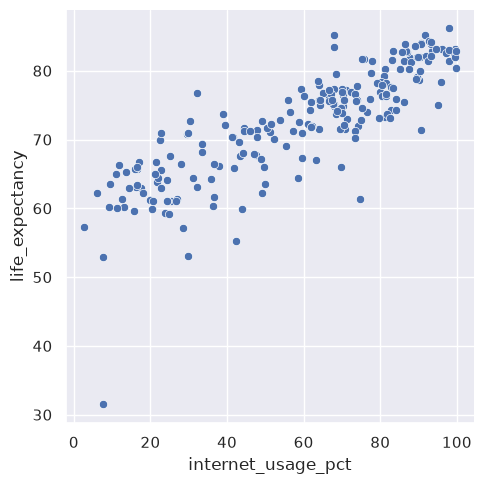

In [19]:
sns.relplot(data = dt, x = 'internet_usage_pct', y = 'life_expectancy')

## Internet Usage vs Life Expectancy

**Observation**: Positive association.

Countries with higher internet usage percentages tend to have higher life expectancy. The scatter plot shows a general upward trend — as internet penetration increases, life expectancy tends to increase as well.

**Note**: This is a correlation, not causation. Internet access itself doesn't directly cause longer life.

Text(0, 0.5, 'Life expectancy')

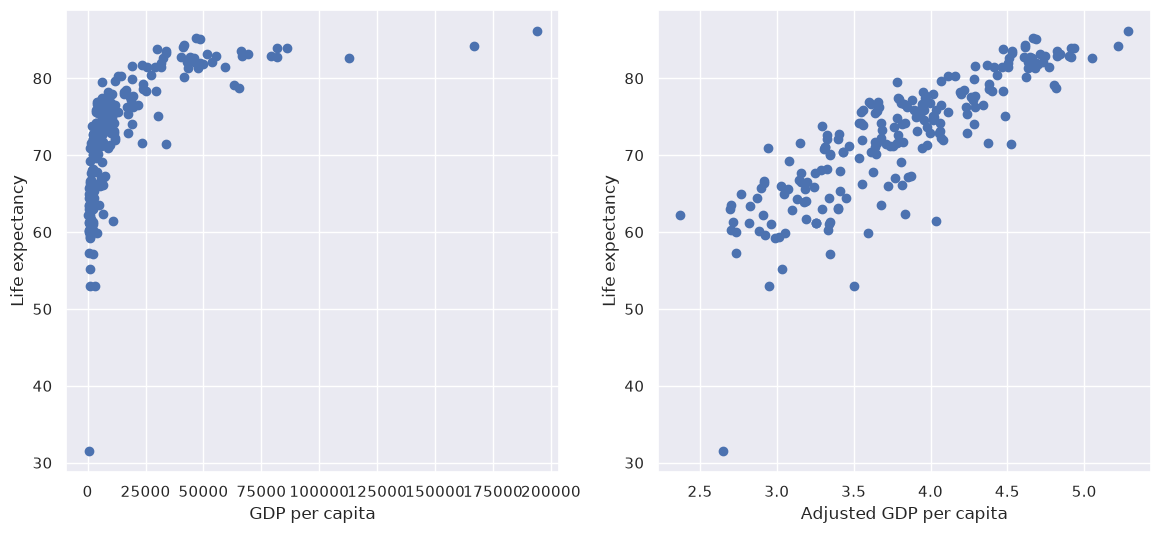

In [33]:
fig, ax = plt.subplots(ncols = 2, figsize= (14, 6))
ax[0].scatter(dt.gdp_per_capita, dt.life_expectancy)
ax[0].set_xlabel("GDP per capita")
ax[0].set_ylabel('Life expectancy')

ax[1].scatter(dt.log_gdp_per_capita, dt.life_expectancy)
ax[1].set_xlabel("Adjusted GDP per capita")
ax[1].set_ylabel('Life expectancy')

## GDP per Capita vs Life Expectancy

**Left plot (raw GDP)**: Strong right skew. Most countries cluster at low GDP per capita (< $20k) with a long tail of wealthy outliers. The relationship is obscured by the scale.

**Right plot (log₁₀ GDP)**: Log transformation reveals a clearer positive linear relationship. Each 10× increase in GDP per capita corresponds to a consistent increase in life expectancy.

**Conclusion**: GDP per capita has a positive association with life expectancy, but the raw distribution is extremely skewed. Log transformation is appropriate for visualization and modeling.

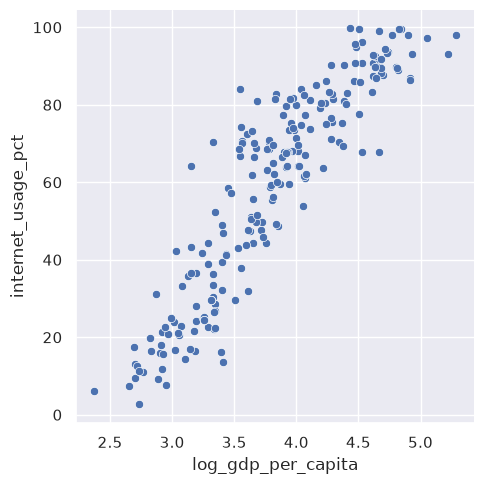

In [40]:
sns.relplot(data = dt, x = 'log_gdp_per_capita', y = 'internet_usage_pct')

## Confounding Variable: GDP per Capita

**Confounder**: GDP per capita (economic development)

**Why it confounds the internet–life expectancy relationship**:

1. **GDP → Internet Usage**: Wealthier countries have better infrastructure, affordability, and education → higher internet penetration
2. **GDP → Life Expectancy**: Wealthier countries have better healthcare, nutrition, sanitation, education → longer life expectancy
3. **Result**: The observed positive correlation between internet usage and life expectancy may be *entirely or partially explained* by underlying economic development

**Potential effect**: Without controlling for GDP, we might incorrectly attribute the life expectancy benefit to internet access itself, when both are actually driven by a country's economic resources. A proper analysis would use multiple regression or stratification by income level to isolate the direct effect of internet usage.